In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [2]:
words = open('./makemore/names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(words))))
stoi = {s:i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [3]:
block_size = 5

def build_dataset(words):
    X, Y = [], []
    for w in words:
        context = [0] * block_size
        for ch in w + '.':
            idx = stoi[ch]
            X.append(context)
            Y.append(idx)
            context = context[1:] + [idx]

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


In [ ]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 20), generator=g)
W1 = torch.randn((100, 500), generator=g)
b1 = torch.randn(500, generator=g) 
W2 = torch.randn((500, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True
    
sum(p.nelement() for p in parameters)

In [ ]:
sum(p.nelement() for p in parameters)

64567

In [6]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre
lri = []
lossi = []
stepi = []


In [ ]:
for i in range(400000):
    # mini batch construct
    idx = torch.randint(0, Xtr.shape[0], (32,)) # size = n

    # forward pass
    emb = C[Xtr[idx]] # Xtr[idx]    shape = n, 5
                      # C[Xtr[idx]] shape = n, 5, 20
                      
    h = torch.tanh(emb.view(-1,100) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[idx])

    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    if i < 100000:
        lr = 0.1
    elif i < 200000:
        lr = 0.01
    elif i < 300000:
        lr = 0.005
    else:
        lr = 0.001

    for p in parameters:
        p.data += -lr * p.grad

    # # track stats
    # lri.append(lre[i])
    lossi.append(loss.log10().item())
    stepi.append(i)

# print(loss.item())


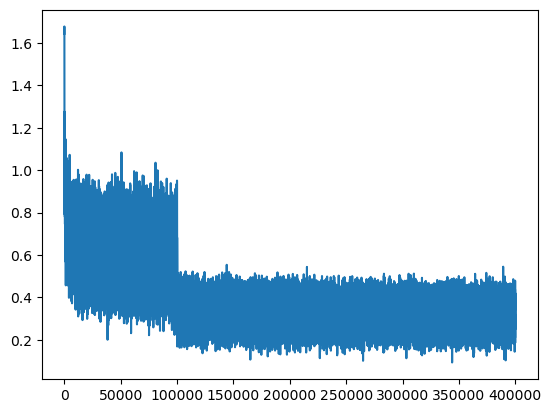

In [8]:
plt.plot(stepi, lossi)

In [9]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, 100) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
print(loss.item())

2.1422171592712402


In [10]:
emb = C[Xdev]
h = torch.tanh(emb.view(-1, 100) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
print(loss.item())

2.2352406978607178


In [11]:

# print(loss.item())
g = torch.Generator().manual_seed(2147483647 + 10)

for i in range(20):
    block_size = 5
    context = [0] * block_size
    out = []
    while True:
        x = C[torch.tensor(context)]
        h = torch.tanh(x.view(1, -1) @ W1 + b1)
        logits = h @ W2 + b2
        probs = torch.softmax(logits, dim=1)
        idx = torch.multinomial(probs, num_samples=1, replacement=True, generator=g).item()
        context = context[1:] + [idx]
        if idx == 0:
            break
        out.append(itos[idx])

    print(''.join(out))


careah
amille
khismy
xheet
khalaya
ejrah
bradelynn
jareen
neraniah
maiir
kaleigh
hamon
cadesian
salilah
jadbi
watelon
jaryxi
jhaen
duraibed
eziiah
